### Linear Regression Assumptions

- **Assumptions** are conditions about the relationship between the features, target, and model errors that support the interpretation and statistical inference of a linear regression model.
- A model can still produce predictions when some assumptions are violated, but coefficient estimates, standard errors, confidence intervals, p-values, or predictions may become unreliable depending on which assumption is violated.
- Assumptions should be checked using plots, domain knowledge, and statistical diagnostics—not by relying on a single test.

#### What can happen when assumptions are violated?

- The model may miss important patterns or produce biased estimates.
- Standard errors and statistical tests may be misleading.
- Predictions may be less accurate, especially in parts of the feature range where the model fits poorly.
- A model can have a high R-squared and still violate important assumptions.

**Important :** Other classical regression conditions also matter, especially independent errors and a correctly specified conditional mean (often expressed as zero conditional mean).

### Assumption 1 - Linearity

**What does it mean?**

- The model assumes that the expected value of the target can be represented as a linear combination of the model's parameters and input features.
- A straight-line relationship between every raw feature and the target is not always required: transformations and polynomial features can represent curved relationships while the model remains linear in its coefficients.
- For multiple regression, inspect whether the model has captured the systematic relationship after accounting for the other predictors.

**What can happen if it is violated?**

- The model may systematically underpredict some values and overpredict others.
- Residuals may show a curve or another visible pattern instead of random scatter.
- Coefficients can give a misleading description of the relationship, and predictive performance may suffer.

**How to check it**

- Plot each feature against the target as an initial exploration.
- Fit the model and inspect residuals versus fitted values. A random cloud around zero is desirable; curves or systematic patterns suggest the mean relationship may be misspecified.
- For multiple predictors, individual scatter plots are only a first look because they do not control for the other predictors.

The following example creates a curved relationship so that the diagnostics can reveal why a straight-line model may be inadequate.


#### Individual scatter plots

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.linear_model import LinearRegression
from scipy import stats

In [2]:
x = 7 * np.random.rand(100, 1) - 2.8
y = 7 * np.random.rand(100, 1) - 2.8

z = x**2 + y**2 + 0.2*x + 0.2*y + 0.1*x*y + 2 + np.random.randn(100,1)

In [3]:
df = pd.DataFrame()

In [4]:
df['x1'] = x.reshape(100) 
df['x2'] = y.reshape(100)
df['y'] = z.reshape(100)

In [5]:
df.head()

,x1,x2,y
0,3.156879,-0.595017,12.348408
1,0.718801,2.155333,8.146303
2,2.885420,3.006035,20.522195
3,3.830907,-0.897283,18.109815
4,0.016242,3.038286,11.773302


Text(0, 0.5, 'Y')

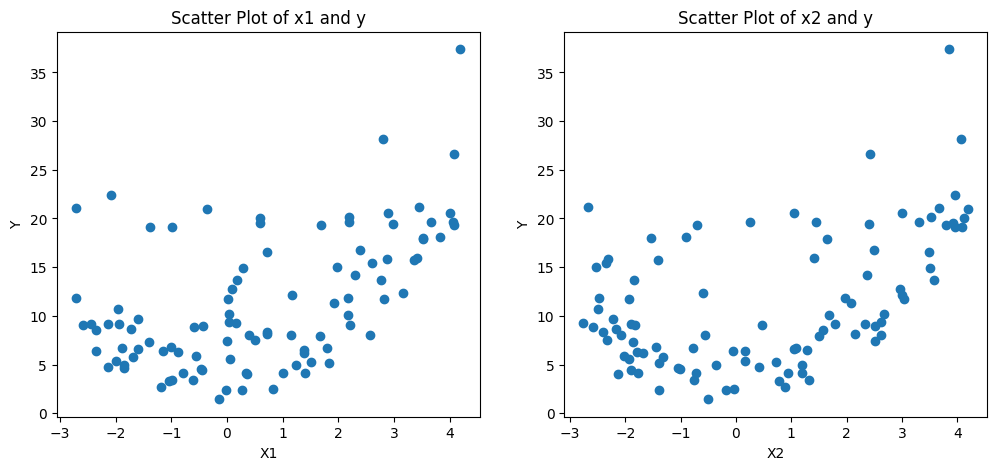

In [6]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,5))

# Plot x1 and y 
ax1.scatter(df['x1'], df['y'])
ax1.set_title('Scatter Plot of x1 and y')
ax1.set_xlabel('X1')
ax1.set_ylabel('Y')

# plot x2 and y 
ax2.scatter(df['x2'], df['y'])
ax2.set_title('Scatter Plot of x2 and y')
ax2.set_xlabel('X2')
ax2.set_ylabel('Y')

#### Residual plot 

In [7]:
# fit a linear regression model 
x = df[['x1', 'x2']]
y = df['y']

model = LinearRegression()

In [8]:
model.fit(x,y)

LinearRegression()

In [9]:
# calculate predicated values and residuals
y_pred = model.predict(x)
residuals = y - y_pred

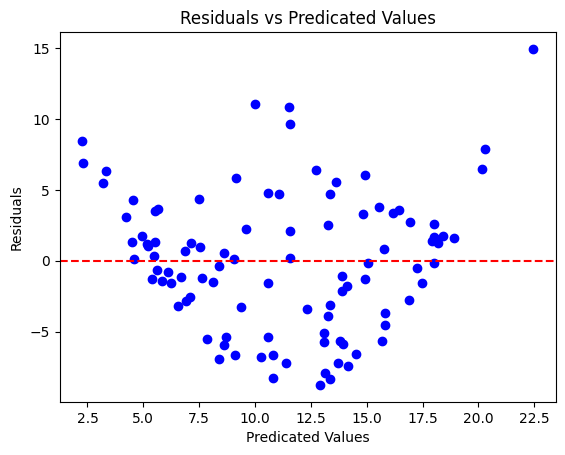

In [10]:
# plot residual against aginst predicated values 
plt.scatter(y_pred, residuals, color='blue')
plt.axhline(y=0, color='red', linestyle='--')
plt.title('Residuals vs Predicated Values')
plt.xlabel('Predicated Values')
plt.ylabel('Residuals');

#### Adding polynomial terms 

In [11]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split

In [12]:
x_train, x_test, y_train, y_test = train_test_split(x,y ,test_size = 0.2, random_state=42)

In [13]:
# fit a linear model 
linear_model = LinearRegression()
linear_model.fit(x_train, y_train)

LinearRegression()

In [14]:
linear_y_pred = linear_model.predict(x_test)

In [15]:
# calculate metrics  for linear model 
linear_r2 = r2_score(y_test, linear_y_pred)
linear_mse = mean_squared_error(y_test,linear_y_pred)

print("R2 Score : ", linear_r2)
print("MSE : ", linear_mse)

R2 Score :  0.030891824258394984
MSE :  19.55322029203358


In [16]:
# Fit a polynomial model 
poly_features = PolynomialFeatures(degree=2)
x_train_poly = poly_features.fit_transform(x_train)
x_test_poly = poly_features.transform(x_test)

In [17]:
poly_model = LinearRegression()

In [18]:
poly_model.fit(x_train_poly, y_train)

LinearRegression()

In [19]:
poly_y_pred = poly_model.predict(x_test_poly)

In [20]:
poly_r2 = r2_score(y_test, poly_y_pred)
poly_mse = mean_squared_error(y_test, poly_y_pred)

In [21]:
# compair model performnace 
print("Linear Model")
print(f"R2 Score : {linear_r2}")
print(f"Mean Squared Error : {linear_mse}")

print("\nPolynomial Model")
print(f"R2 Score : {poly_r2}")
print(f"Mean Squared Error : {poly_mse}")

Linear Model
R2 Score : 0.030891824258394984
Mean Squared Error : 19.55322029203358

Polynomial Model
R2 Score : 0.9313048697087258
Mean Squared Error : 1.3860279473417363


#### What to do when linearity is violated

- **Transform a variable:** try a scientifically sensible transformation such as `log(y)`, `sqrt(y)`, or `log(x)` when the data and interpretation support it. Check that the transformed values are valid (for example, logarithms require positive values).
- **Add polynomial features:** include terms such as $x^2$ or $x^3$ when a curved pattern is plausible. Polynomial regression is still linear in its coefficients.
- **Add interactions:** include a term such as $x_1x_2$ when the effect of one feature may depend on another.
- **Use a different model:** splines or tree-based models may be appropriate when the relationship is more complex.

After changing the model, compare performance on held-out data and inspect the residual plot again. Do not choose a transformation only because it increases training R-squared.


#### 1. Transformations

In [22]:
# Generate a non-linear dataset with a quadratic relationship
np.random. seed(42)
x = 10 * np.random.rand(100, 1)
y = x ** 2+5+ np.random.normal(0, 5, (100, 1))
y = np.abs(y) # Ensure y is non-negative

# Apply square root transformation to y
y_sqrt = np.sqrt(y)

# Fit linear regression models for the original and transformed data
linear_model_original = LinearRegression()
linear_model_original.fit(x, y)
linear_model_transformed = LinearRegression()
linear_model_transformed.fit(x, y_sqrt)

# Predictions
y_pred_original = linear_model_original.predict(x)
y_pred_transformed = linear_model_transformed.predict(x)

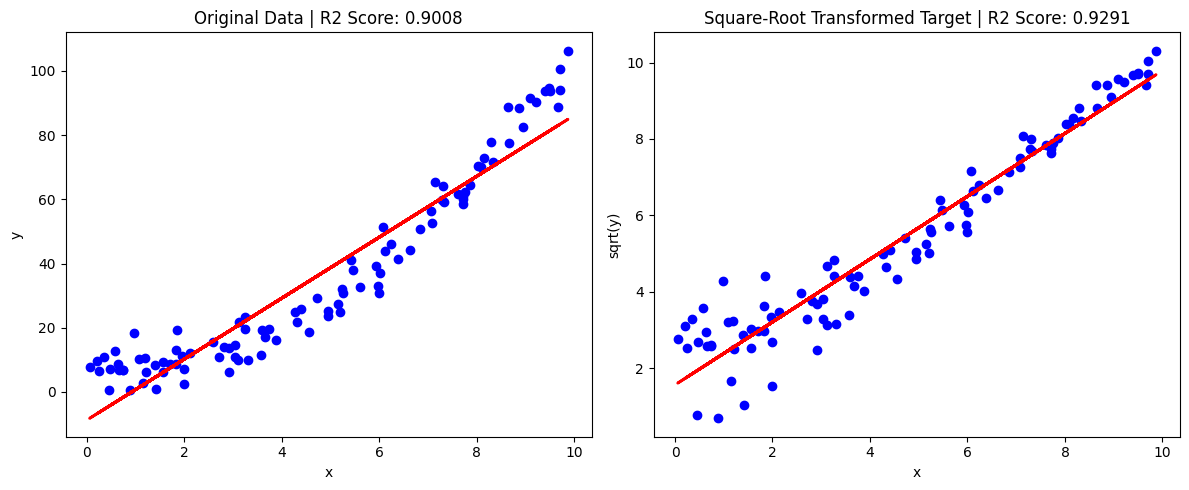

Original target scale
R-squared: 0.9008

Square-root transformed target scale
R-squared: 0.9291


In [23]:
# Calculate R-squared before using the values in plot titles
r2_original = r2_score(y, y_pred_original)
r2_transformed = r2_score(y_sqrt, y_pred_transformed)

# Visualize the relationship before and after transformation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.scatter(x, y, color='blue')
ax1.plot(x, y_pred_original, color='red', linewidth=2)
ax1.set_title(f'Original Data | R2 Score: {r2_original:.4f}')
ax1.set_xlabel('x')
ax1.set_ylabel('y')

ax2.scatter(x, y_sqrt, color='blue')
ax2.plot(x, y_pred_transformed, color='red', linewidth=2)
ax2.set_title(f'Square-Root Transformed Target | R2 Score: {r2_transformed:.4f}')
ax2.set_xlabel('x')
ax2.set_ylabel('sqrt(y)')

plt.tight_layout()
plt.show()

print("Original target scale")
print(f"R-squared: {r2_original:.4f}")

print("\nSquare-root transformed target scale")
print(f"R-squared: {r2_transformed:.4f}")

# Note: these R-squared values use different target scales,
# so they should not be compared as if they measured the same outcome.


#### 2. Polynomial regression 

In [24]:
# Generate a non-linear dataset with a quadratic relationship
np.random.seed(42)
x= 10 * np.random.rand(100, 1)
y = x ** 2 + 5+ np.random.normal(0, 5,(100, 1))
y= np.abs(y) # Ensure y is non-negative

# Fit linear regression model
linear_model = LinearRegression()
linear_model.fit(x, y)
y_pred_linear = linear_model.predict(x)

# Fit polynomial regression model (degree = 2)
poly_features = PolynomialFeatures(degree=2, include_bias=False)
x_poly = poly_features.fit_transform(x)
poly_model = LinearRegression()
poly_model.fit(x_poly, y)
y_pred_poly = poly_model.predict(x_poly)

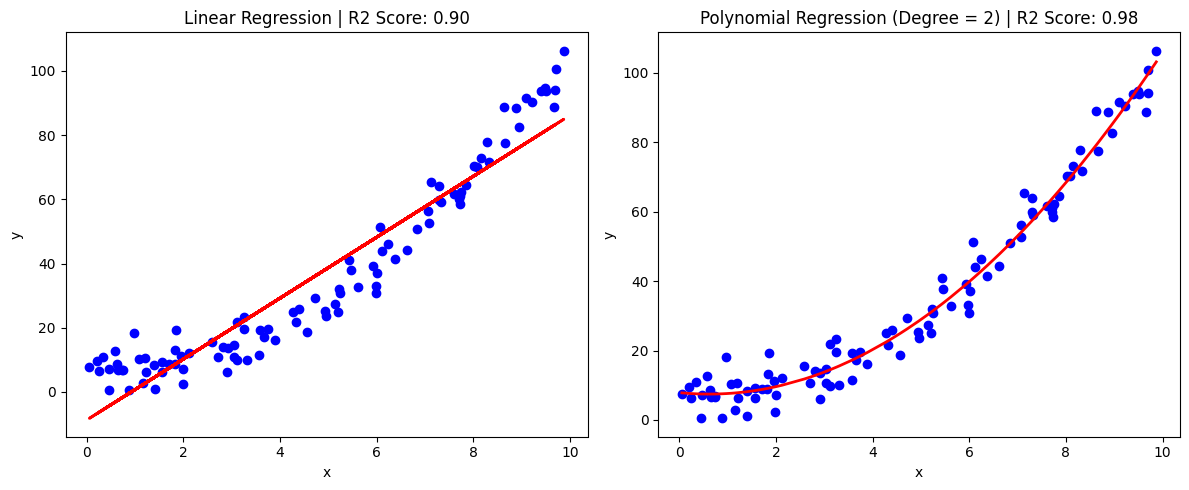

Linear Regression R-squared: 0.9008
Polynomial Regression R-squared: 0.9782


In [25]:
# Calculate R-squared before using the values in plot titles
r2_linear = r2_score(y, y_pred_linear)
r2_poly = r2_score(y, y_pred_poly)

# Visualize the fitted linear and polynomial models
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.scatter(x, y, color='blue')
ax1.plot(x, y_pred_linear, color='red', linewidth=2)
ax1.set_title(f'Linear Regression | R2 Score: {r2_linear:.2f}')
ax1.set_xlabel('x')
ax1.set_ylabel('y')

sort_idx = np.argsort(x[:, 0])
ax2.scatter(x, y, color='blue')
ax2.plot(x[sort_idx, 0], y_pred_poly[sort_idx], color='red', linewidth=2)
ax2.set_title(f'Polynomial Regression (Degree = 2) | R2 Score: {r2_poly:.2f}')
ax2.set_xlabel('x')
ax2.set_ylabel('y')

plt.tight_layout()
plt.show()

print(f"Linear Regression R-squared: {r2_linear:.4f}")
print(f"Polynomial Regression R-squared: {r2_poly:.4f}")


### Assumption 2 - Normality of residuals

**What does it mean?**

- The assumption concerns the model's **errors/residuals**, not the raw feature columns or necessarily the target variable.
- In the classical linear model, errors are assumed to be approximately normally distributed conditional on the predictors.
- Normality is mainly needed for exact t-tests, F-tests, and confidence intervals in small samples. OLS coefficient estimation itself does not require normally distributed errors.

**What can happen if it is violated?**

- In small samples, p-values and confidence intervals based on normal-theory inference may be less reliable.
- Strong skewness or heavy tails can indicate outliers, omitted variables, a wrong functional form, or a non-normal error process.
- With sufficiently large samples, inference may often be approximately valid under additional conditions, but severe outliers and dependence still need attention.

**How to check it**

- **Histogram:** look for a roughly symmetric, bell-shaped residual distribution. Minor deviations are common.
- **Q-Q plot:** points should lie approximately along the reference line. Systematic curves or large tail departures indicate non-normality.
- **Omnibus / D'Agostino-Pearson test:** the null hypothesis is that the sample comes from a normal distribution. A small p-value (often below 0.05) is evidence against normality. A large p-value does not prove normality.
- Always combine tests with plots and context; tests are sensitive to sample size.


#### Histogram and Q-Q plot 

In [26]:
# Generate a synthetic dataset - with linearity
np.random.seed(42)
x = np.random.rand(100, 1)
y=3*x+ np.random.normal(0, 0.3, (100,1))
# Fit a linear regression model
model = LinearRegression()
model.fit(x, y)
y_pred = model.predict(x)

# Calculate the residuals (error terms)
residuals = y - y_pred

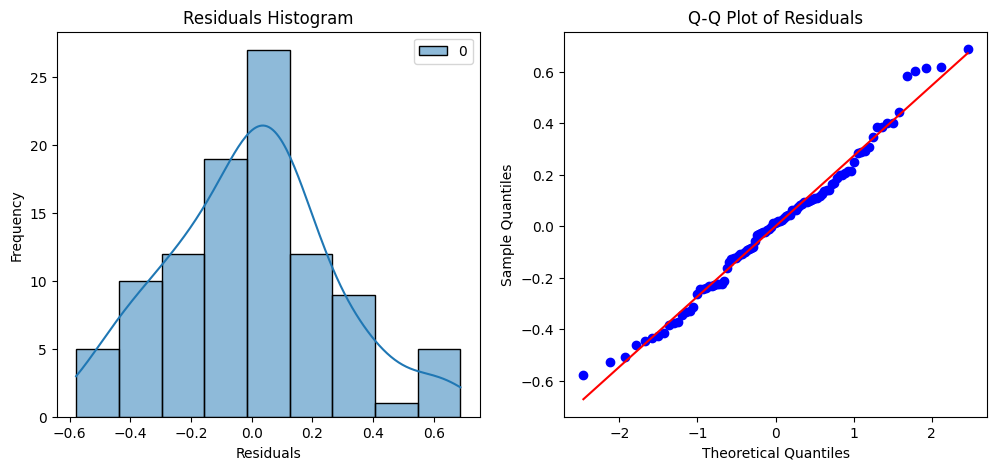

In [27]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,5))

# Histogram
sns.histplot(residuals, kde=True, ax=ax1)
ax1.set_title('Residuals Histogram')
ax1.set_xlabel('Residuals')
ax1.set_ylabel('Frequency')

# QQ plot 
stats.probplot(residuals.flatten(), plot=ax2)
ax2.set_title('Q-Q Plot of Residuals')
ax2.set_xlabel('Theoretical Quantiles')
ax2.set_ylabel('Sample Quantiles')

plt.show()

In [28]:
mean_residuals = np.mean(residuals)
print(f"Mean of Residuals : {mean_residuals:.4f}")

Mean of Residuals : 0.0000


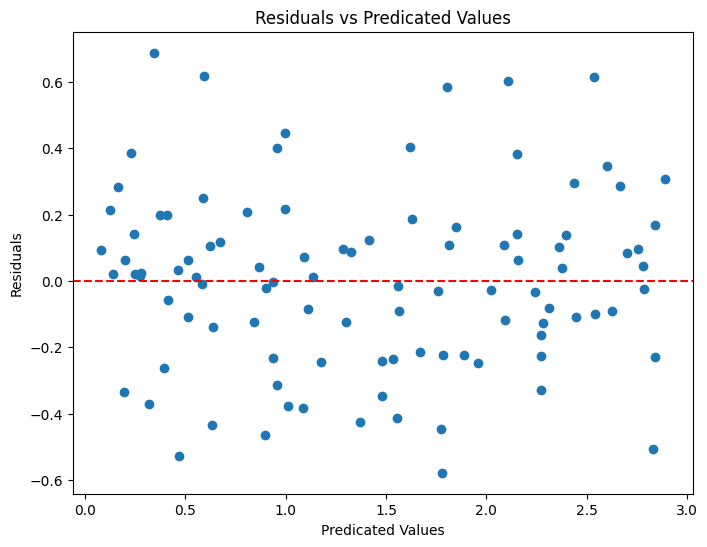

In [29]:
# residuals plot :- if no pattern than its show that error are noramliy distributed 
plt.figure(figsize=(8,6))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Residuals vs Predicated Values')
plt.xlabel('Predicated Values')
plt.ylabel("Residuals")

plt.show()

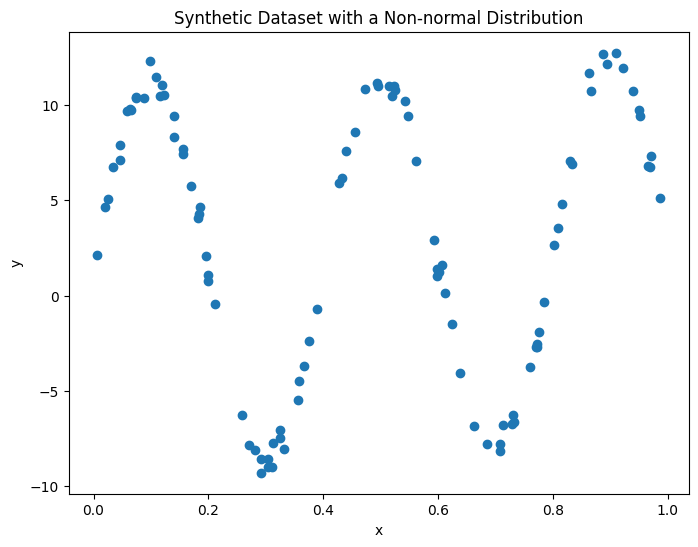

In [30]:
# Generate a synthetic dataset with a non-normal distribution

np.random.seed(42)
x = np.random.rand(100, 1)
y= np.exp(x)+10*np.sin(5*np.pi*x) + np.random.normal(0, 0.5, (100, 1))

# Visualize the dataset
plt.figure(figsize=(8,6))
plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Synthetic Dataset with a Non-normal Distribution')
plt.show()

In [31]:
# Fit a linear regression model
model = LinearRegression()
model.fit(x, y)
y_pred = model.predict(x)

# Calculate the residuals (error terms)
residuals = y - y_pred

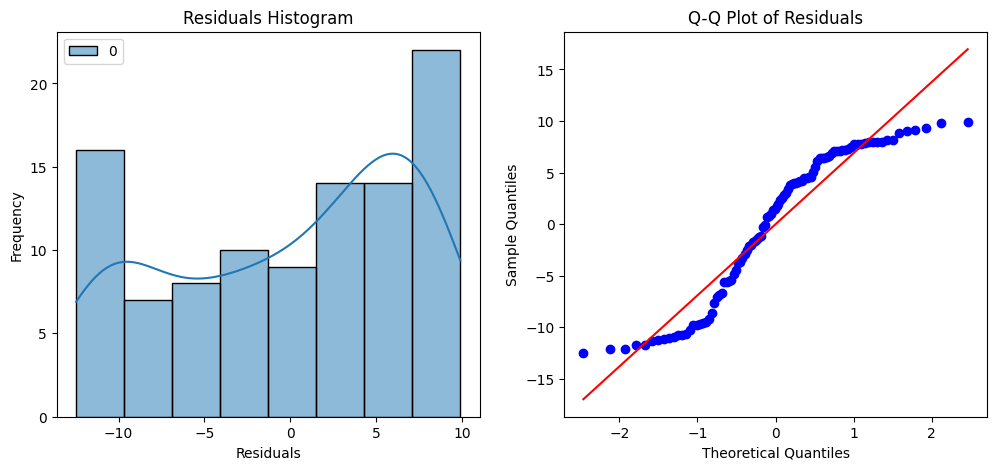

In [32]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,5))

# Histogram
sns.histplot(residuals, kde=True, ax=ax1)
ax1.set_title('Residuals Histogram')
ax1.set_xlabel('Residuals')
ax1.set_ylabel('Frequency')

# Q-Q plot
stats.probplot(residuals.flatten(), plot=ax2)
ax2.set_title('Q-Q Plot of Residuals')
ax2.set_xlabel('Theoretical Quantiles')
ax2.set_ylabel('Sample Quantiles')

plt.show()

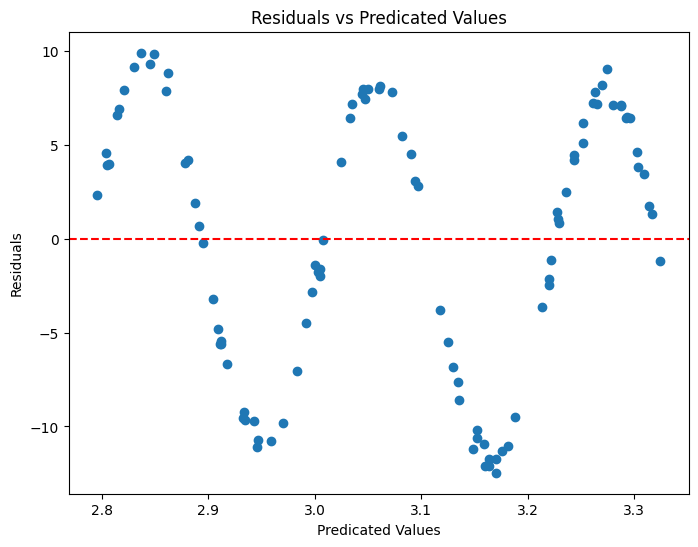

In [33]:
plt.figure(figsize=(8,6))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Residuals vs Predicated Values')
plt.xlabel('Predicated Values')
plt.ylabel("Residuals")

plt.show()

#### Omnibus test

In [34]:
# Generate a synthetic dataset - with linearity
np.random.seed(42)
x = np.random.rand(100, 1)
y=3 * x + np.random.normal(0, 0.3, (100,1))

# Fit a linear regression model
model = LinearRegression()
model.fit(x, y)
y_pred = model.predict(x)

# Calculate the residuals (error terms)
residuals = y - y_pred

skewness = stats.skew(residuals)
kurtosis = stats.kurtosis(residuals)
omnibus_stats, omnibus_p_value = stats.normaltest(residuals)

print(f"Skewness : {skewness[0]:.4f}")
print(f"Kurtosis : {kurtosis[0]:.4f}")
print(f"Omnibus test statistic : {omnibus_stats[0]:.4f}")
print(f"Omnibus test P value : {omnibus_p_value[0]:.4f}")

Skewness : 0.2173
Kurtosis : -0.0712
Omnibus test statistic : 0.9002
Omnibus test P value : 0.6376


**How to interpret the Omnibus test:** its null hypothesis is that the residuals are normally distributed. If the p-value is below a chosen significance level (commonly 0.05), reject the normality null. If it is above 0.05, there is not enough evidence to reject normality; this does not prove the residuals are normal.

In [35]:
np.random.seed(42)
x = np.random.rand(100, 1)
y= np.exp(x)+10*np.sin(5*np.pi*x) + np.random.normal(0, 0.5, (100, 1))

# Fit a linear regression model
model = LinearRegression()
model.fit(x, y)
y_pred = model.predict(x)

# Calculate the residuals (error terms)
residuals = y - y_pred

skewness = stats.skew(residuals)
kurtosis = stats.kurtosis(residuals)
omnibus_stats, omnibus_p_value = stats.normaltest(residuals)

print(f"Skewness : {skewness[0]:.4f}")
print(f"Kurtosis : {kurtosis[0]:.4f}")
print(f"Omnibus test statistic : {omnibus_stats[0]:.4f}")
print(f"Omnibus test P value : {omnibus_p_value[0]:.4f}")

Skewness : -0.3717
Kurtosis : -1.2746
Omnibus test statistic : 50.6234
Omnibus test P value : 0.0000


#### What to do when residual normality is violated

1. **Check unusual observations:** investigate data-entry errors, influential points, and whether the observations belong to the population being modelled. Do not delete valid observations merely to make a test pass.
2. **Revisit model specification:** omitted nonlinear terms, interactions, or important predictors can create structured residuals.
3. **Consider a response transformation:** for positive, right-skewed targets, a log or square-root transformation may help if scientifically appropriate. Interpret predictions on the transformed scale carefully; converting them back may require a bias adjustment.
4. **Use inference methods suited to the problem:** for larger samples, robust standard errors or bootstrap confidence intervals may be useful. For a non-normal outcome with a suitable distribution, consider a generalized linear model.
5. **Re-check diagnostics:** fit the revised model and inspect its residual histogram and Q-Q plot again.

A residuals-versus-fitted plot is primarily useful for checking functional form and changing variance; it is not, by itself, a normality test.


### Assumption 3 - Homoscedasticity (constant error variance)

**What does it mean?**

- Homoscedasticity means the variance of the errors is approximately constant across the range of fitted values or predictor values.
- In a residuals-versus-fitted plot, the vertical spread should be roughly similar from left to right.

**What can happen if it is violated?**

- OLS coefficients can remain unbiased under the usual exogeneity conditions, but conventional standard errors may be incorrect.
- As a result, t-statistics, p-values, and confidence intervals can be misleading.
- Prediction intervals may be poorly calibrated, and the model may be less precise in some regions.

**How to check it**

- Plot residuals against fitted values and look for a funnel or fan shape (the spread grows or shrinks).
- Plot residuals against each important feature when useful.
- A Breusch-Pagan test can formally test whether residual variance is related to the predictors. Its null hypothesis is constant variance; a small p-value is evidence of heteroscedasticity.

The next code cell gives a complete example using a fitted model, a residual plot, and the Breusch-Pagan test.


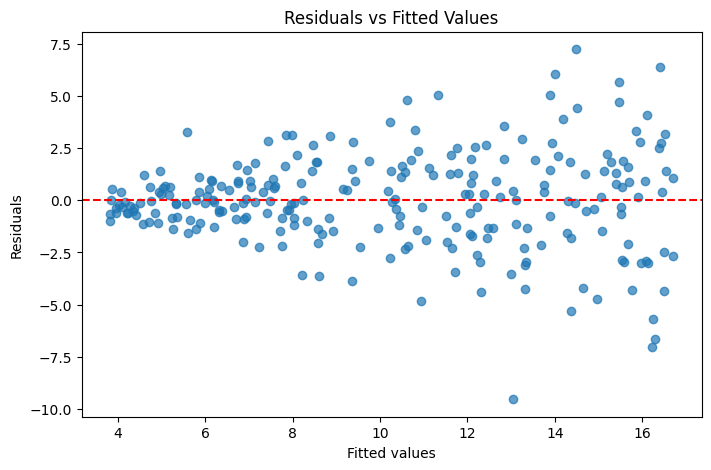

Breusch-Pagan LM p-value: 1.788e-09
Breusch-Pagan F-test p-value: 4.927e-10


In [36]:
# Example: check homoscedasticity with a residual plot and Breusch-Pagan test
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

# Use the existing synthetic data (x and y) if they are still defined.
# This cell creates a fresh example so it can also run independently.
np.random.seed(42)
x_hetero = np.random.uniform(1, 10, 250)
noise_scale = 0.4 * x_hetero
y_hetero = 2 + 1.5 * x_hetero + np.random.normal(0, noise_scale)

X_hetero = sm.add_constant(x_hetero)
ols_hetero = sm.OLS(y_hetero, X_hetero).fit()
fitted_hetero = ols_hetero.fittedvalues
resid_hetero = ols_hetero.resid

plt.figure(figsize=(8, 5))
plt.scatter(fitted_hetero, resid_hetero, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")
plt.show()

bp_lm, bp_lm_pvalue, bp_f, bp_f_pvalue = het_breuschpagan(
    resid_hetero, ols_hetero.model.exog
)
print(f"Breusch-Pagan LM p-value: {bp_lm_pvalue:.4g}")
print(f"Breusch-Pagan F-test p-value: {bp_f_pvalue:.4g}")

# A small p-value (commonly < 0.05) is evidence against constant error variance.


### Assumption 4 - Multicollinearity

**What does it mean?**

- Multicollinearity occurs when two or more independent variables are strongly linearly related.
- Perfect multicollinearity means one predictor can be written exactly as a linear combination of other predictors; the model cannot uniquely estimate all corresponding coefficients.
- High but imperfect multicollinearity does not necessarily make predictions poor, but it can make individual coefficients unstable and difficult to interpret.

**What can happen if it is violated?**

- Coefficient estimates can have large standard errors and wide confidence intervals.
- Coefficients may change substantially when data or model features change.
- A predictor may have a high p-value even when the model has a strong overall fit.
- The model may struggle to separate the individual effects of correlated predictors.

**How to check it**

- **Correlation matrix:** inspect pairwise correlations among predictors. Values around $+0.8$ or $-0.8$ can be a warning, but pairwise correlation can miss multivariable relationships.
- **Variance Inflation Factor (VIF):** measures how much the variance of a coefficient is inflated because of linear relationships with the other predictors. VIF near 1 indicates little inflation; values above 5 are often investigated, and values above 10 are commonly treated as serious warning signs. These are rules of thumb, not absolute cutoffs.
- **Condition number:** a large value can indicate scaling problems or near-dependencies in the design matrix. It depends on feature scaling and model setup, so standardize predictors before using it as a multicollinearity diagnostic.

The following cells use the Advertising dataset and explicitly select the predictor columns so the target is not accidentally included in the VIF calculation.


#### Correlation

In [37]:
df = pd.read_csv('https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv')
# Keep the three advertising predictors explicit for correlation and VIF analysis.
predictor_cols = ['TV', 'Radio', 'Newspaper']

In [38]:
df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


The heatmap shows pairwise correlations. Focus on relationships among the predictors (`TV`, `Radio`, and `Newspaper`); correlation with the target is not a multicollinearity diagnostic.

<Axes: >

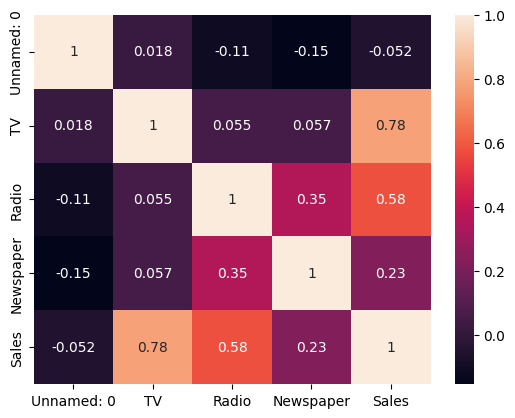

In [39]:
sns.heatmap(df.corr(), annot=True)

#### Variance Inflation Factor (VIF)

In [40]:
# Calculate VIF for the predictor variables only
from statsmodels.stats.outliers_influence import variance_inflation_factor

predictor_cols = ["TV", "Radio", "Newspaper"]
X_vif = df[predictor_cols].astype(float)

vif_table = pd.DataFrame({
    "Feature": predictor_cols,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})
display(vif_table)

# VIF is commonly interpreted as:
# around 1: little multicollinearity
# above 5: investigate
# above 10: potentially serious (context matters)


,Feature,VIF
0,TV,1.004611
1,Radio,1.144952
2,Newspaper,1.145187


#### Condition number  

In [41]:
# Condition number after standardizing predictors
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X_vif)
condition_number = np.linalg.cond(X_scaled)

print(f"Condition number (standardized predictors): {condition_number:.2f}")
# A large condition number can indicate near-dependencies.
# The cutoff depends on scaling and context; do not use 30 as a universal rule.


Condition number (standardized predictors): 1.46


#### What to do when multicollinearity is high

- **Remove one of a pair of redundant predictors** when there is a sound subject-matter reason and the removed feature is not essential.
- **Combine related predictors** into a meaningful index or use dimensionality reduction such as PCA when appropriate.
- **Collect more informative data** if the predictors move together in the available sample.
- **Use regularization** such as Ridge regression when prediction is the priority; regularization can stabilize estimates, but it changes the estimation method and coefficient interpretation.
- **Keep correlated predictors** when they are important for prediction or required by the subject matter, while being cautious about interpreting their individual coefficients.

Do not remove features solely because their correlation exceeds a fixed threshold. Consider the goal of the model, domain knowledge, VIF, and validation performance.


### Quick Revision: Assumption, Diagnostic, and Possible Remedy

| Assumption | Useful checks | Possible response when violated |
|---|---|---|
| Linearity | Feature plots; residuals vs fitted | Add justified transformations, polynomial terms, interactions, splines, or use another model |
| Normality of residuals | Histogram; Q-Q plot; Omnibus / normality test | Investigate outliers and specification; consider transformation, bootstrap, robust inference, or an appropriate GLM |
| Homoscedasticity | Residuals vs fitted; Breusch-Pagan test | HC3 robust standard errors, WLS, or a justified transformation/variance model |
| No severe multicollinearity | Predictor correlation matrix; VIF; condition number | Remove/combine redundant predictors, collect more data, use PCA or regularization |

### Key Takeaways

1. Assumptions are conditions that help make regression estimates and statistical inference meaningful.
2. Always inspect residuals after fitting a model; a high R-squared does not guarantee that assumptions hold.
3. Normality applies to the errors/residuals, not to every feature.
4. Heteroscedasticity mainly affects conventional standard errors and inference; robust standard errors can help with that issue.
5. Multicollinearity makes individual coefficients less stable and harder to interpret, but does not automatically make predictions inaccurate.
6. A diagnostic test is evidence, not a final verdict. Use plots, context, and more than one diagnostic.
7. After any remedy, refit the model and check the assumptions again.
